<a href="https://colab.research.google.com/github/ortizo-117/BMEG_591Q_group_project/blob/master/Copy_of_LabC2_clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BMEG 400Q-591Q : Lab C Pt.2


---

Mounting Colab to get the Data


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
#TO-DO: Modify this path to point to your data folder
path_to_data = os.path.join("/content/drive/MyDrive", "BMEG591Q-Data")

We will use diabetes.csv from
https://www.kaggle.com/datasets/mathchi/diabetes-data-set

In [ ]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


768

768

In [ ]:
# Set your path to the CSV
CSV_PATH = os.path.join(path_to_data, "diabetes.csv")

In [ ]:
df = pd.read_csv(CSV_PATH)
print("Shape:", df.shape)
df.head()


Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
#META-DATA
print("Summary stats:")
display(df.describe(include='all'))

print("\nMissing values per column:")
print(df.isna().sum())

print("\nClass balance:")
#TO-DO: find & print the class distribution





Summary stats:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Missing values per column:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Class balance:


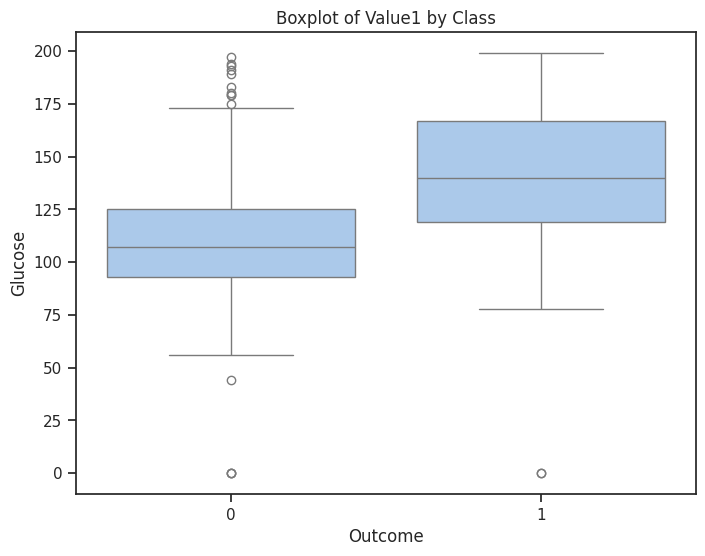

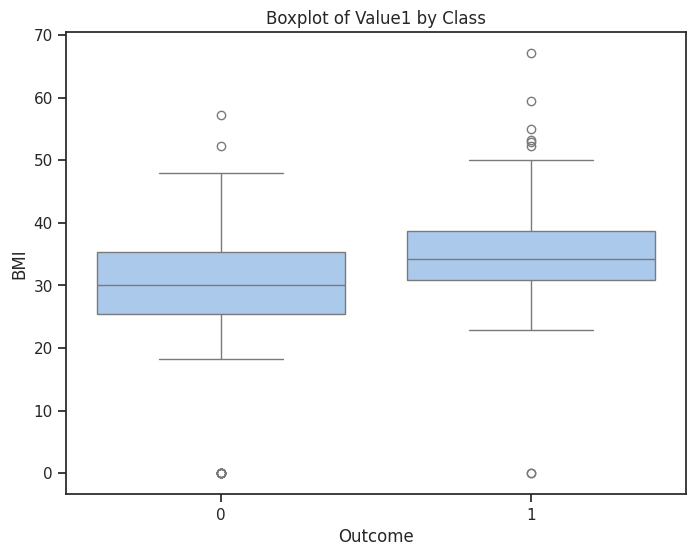

In [ ]:
#TO-DO: find & print the class distribution
import matplotlib.pyplot as plt
import seaborn as sns

# Set a nice style for the plots
sns.set_theme(style="ticks", palette="pastel")

# Create a boxplot for 'Value1' grouped by 'Class'
plt.figure(figsize=(8, 6))
sns.boxplot(x='Outcome', y='Glucose', data=df)
plt.title('Boxplot of Value1 by Class')
plt.show()

# Create a boxplot for 'Value1' grouped by 'Class'
plt.figure(figsize=(8, 6))
sns.boxplot(x='Outcome', y='BMI', data=df)
plt.title('Boxplot of Value1 by Class')
plt.show()



### Utility Function - Evaluation

Reference sklearn.metrics library and implement the following:

In [ ]:
def evaluate_model(clf, Xtr, ytr, Xte, yte, name:str):
    """Fit classifier, print metrics, draw ROC curve and confusion matrix."""
    clf.fit(Xtr, ytr)
    y_proba = clf.predict_proba(Xte)[:,1] if hasattr(clf, "predict_proba") else None
    y_pred = clf.predict(Xte)

    # ROC-AUC
    if y_proba is not None:
        auc = roc_auc_score(yte, y_proba)
        print(f"[{name}] ROC-AUC: {auc:.3f}")
        fpr, tpr, _ = roc_curve(yte, y_proba)

        plt.figure(figsize=(6,5))
        plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
        plt.plot([0,1],[0,1], linestyle='--')
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title(f"ROC Curve – {name}")
        plt.legend()
        plt.show()
    else:
        print(f"[{name}] predict_proba not available; skipping ROC.")

    # Confusion matrix
    #TO-DO: find confusion matrix
    cm = confusion_matrix(yte, y_pred)
    print(f"[{name}] Confusion Matrix:\n{cm}")

    plt.figure(figsize=(4,4))
    plt.imshow(cm, interpolation='nearest')
    plt.title(f"Confusion Matrix – {name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.xticks([0,1],[0,1])
    plt.yticks([0,1],[0,1])
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, cm[i, j], ha="center", va="center")
    plt.tight_layout()
    plt.show()

    # Classification report
    print(f"[{name}] Classification Report:")
    #TO-DO: print classification report
    print(classification_report(yte, y_pred))


### Train/Test Split

In [ ]:
FEATURES = ['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']
TARGET = 'Outcome'

X = df[FEATURES].copy()
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    #TO-DO: write this code
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y

)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)


Train shape: (614, 8) | Test shape: (154, 8)


### t-SNE

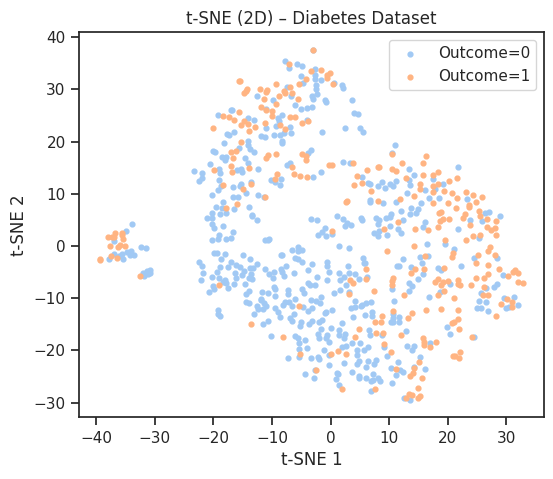

In [ ]:
#Standardization
Xs = StandardScaler().fit_transform(X)
Xp = PCA(n_components=min(8, X.shape[1]), random_state=RANDOM_STATE).fit_transform(Xs)

#t-SNE
tsne = TSNE(n_components=2, perplexity=30, learning_rate='auto', init='pca', random_state=RANDOM_STATE)
X_emb = tsne.fit_transform(Xp)

plt.figure(figsize=(6,5))
for label in sorted(y.unique()):
    mask = (y.values == label)
    plt.scatter(X_emb[mask,0], X_emb[mask,1], label=f"Outcome={label}", s=12)
plt.title("t-SNE (2D) – Diabetes Dataset")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend()
plt.show()


### kNN Classifier

In [ ]:
knn_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

Hyperparameter Tuning

In [ ]:
param_grid = {
    'knn__n_neighbors': [3,5,7,9,11,15,16,40,60],
    'knn__weights': ['uniform','distance'],
    'knn__p': [1,2,3]
}

In [ ]:
grid_knn = GridSearchCV(knn_pipe, param_grid, scoring='roc_auc', cv=5, n_jobs=-1)
grid_knn.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('knn', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'knn__n_neighbors': [3, 5, 7, 9, 11, 15, 16, 40, 60],
                         'knn__p': [1, 2, 3],
                         'knn__weights': ['uniform', 'distance']},
             scoring='roc_auc')

In [ ]:
print("Best KNN params: ") #TO-DO: print best params found
print(grid_knn.best_params_)
print("Best CV AUC: ") #TO-DO: print AUC
print(grid_knn.best_score_)


Best KNN params: 
{'knn__n_neighbors': 60, 'knn__p': 1, 'knn__weights': 'distance'}
Best CV AUC: 
0.8336641749723146


[KNN (best)] ROC-AUC: 0.809


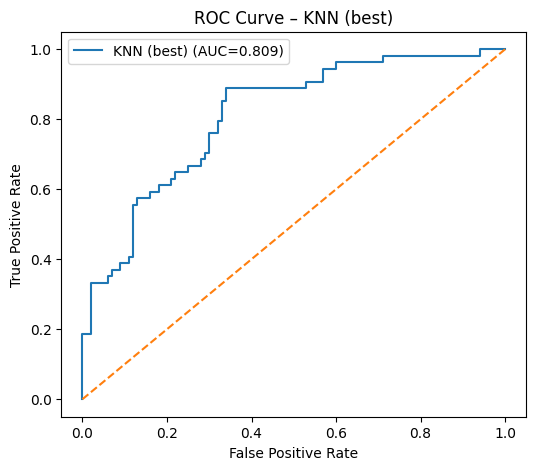

[KNN (best)] Confusion Matrix:
[[91  9]
 [34 20]]


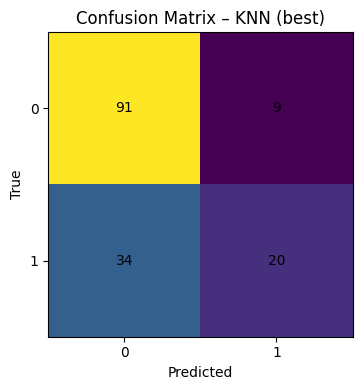

[KNN (best)] Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.91      0.81       100
           1       0.69      0.37      0.48        54

    accuracy                           0.72       154
   macro avg       0.71      0.64      0.65       154
weighted avg       0.71      0.72      0.69       154



In [ ]:
best_knn = grid_knn.best_estimator_
evaluate_model(best_knn, X_train, y_train, X_test, y_test, name="KNN (best)")


### Decision Tree

In [ ]:
dt = DecisionTreeClassifier(random_state=RANDOM_STATE)

In [ ]:
param_grid_dt = {
    'max_depth': [None, 3, 4, 5, 6, 8, 10],
    'min_samples_leaf': [1, 2, 4, 6, 10],
    'criterion': ['gini', 'entropy']
}


In [ ]:
grid_dt = GridSearchCV(dt, param_grid_dt, scoring='roc_auc', cv=5, n_jobs=-1)
grid_dt.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [None, 3, 4, 5, 6, 8, 10],
                         'min_samples_leaf': [1, 2, 4, 6, 10]},
             scoring='roc_auc')

In [ ]:
print("Best DT params: ") #TO-DO: print best params found
print(grid_dt.best_params_)
print("Best CV AUC: ") #TO-DO: print AUC found
print(grid_dt.best_score_)

Best DT params: 
{'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 10}
Best CV AUC: 
0.8023588039867111


[Decision Tree (best)] ROC-AUC: 0.796


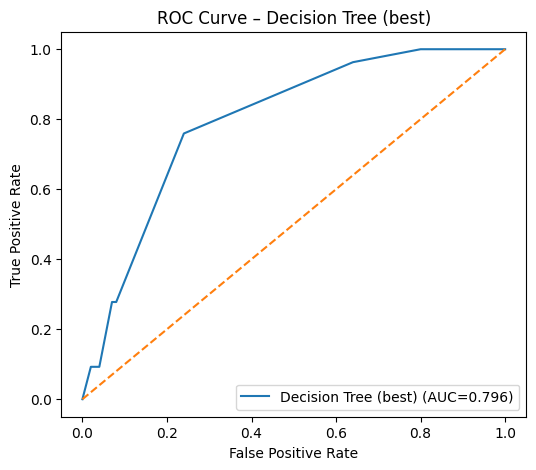

[Decision Tree (best)] Confusion Matrix:
[[92  8]
 [39 15]]


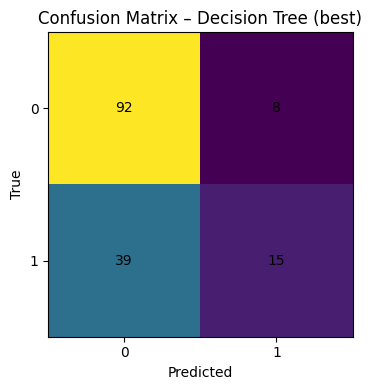

[Decision Tree (best)] Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.92      0.80       100
           1       0.65      0.28      0.39        54

    accuracy                           0.69       154
   macro avg       0.68      0.60      0.59       154
weighted avg       0.68      0.69      0.65       154



In [ ]:
best_dt = grid_dt.best_estimator_
evaluate_model(best_dt, X_train, y_train, X_test, y_test, name="Decision Tree (best)")


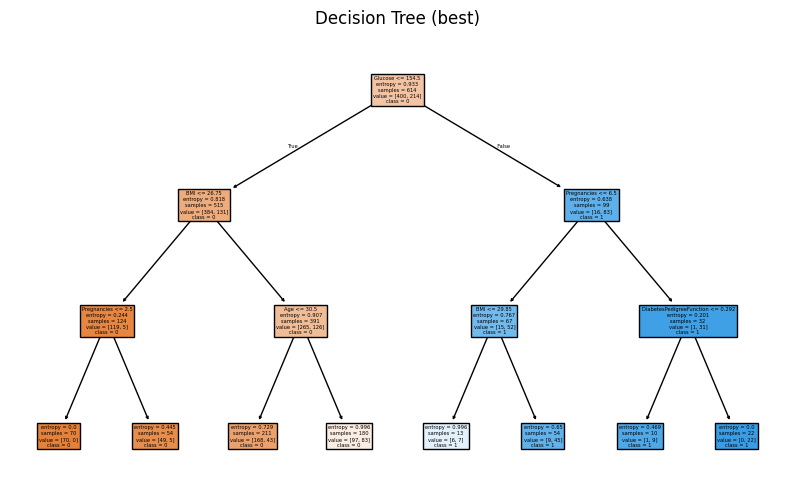

In [ ]:
# Visualize the tree (small max_depth recommended for readability)
plt.figure(figsize=(10,6))
plot_tree(best_dt, feature_names=FEATURES, class_names=['0','1'], filled=True)
plt.title("Decision Tree (best)")
plt.show()

### Random Forest

In [ ]:
rf = RandomForestClassifier(random_state=RANDOM_STATE)

In [ ]:
param_grid_rf = {
    'n_estimators': [100, 200, 400],
    'max_depth': [None, 4, 6, 8, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None]
}

In [ ]:
grid_rf = GridSearchCV(rf, param_grid_rf, scoring='roc_auc', cv=5, n_jobs=-1)
grid_rf.fit(X_train, y_train)


GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 4, 6, 8, 10],
                         'max_features': ['sqrt', 'log2', None],
                         'min_samples_leaf': [1, 2, 4],
                         'n_estimators': [100, 200, 400]},
             scoring='roc_auc')

In [ ]:
print("Best RF params: ") #TO-DO: print best params found
print(grid_rf.best_params_)
print("Best CV AUC: ") #TO-DO: print AUC found
print(grid_rf.best_score_)

Best RF params: 
{'max_depth': 4, 'max_features': 'log2', 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV AUC: 
0.8374446290143964


[Random Forest (best)] ROC-AUC: 0.812


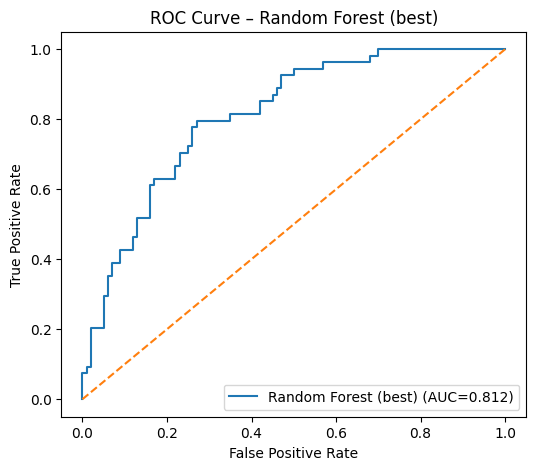

[Random Forest (best)] Confusion Matrix:
[[86 14]
 [26 28]]


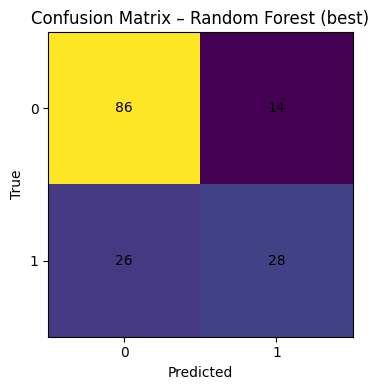

[Random Forest (best)] Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.86      0.81       100
           1       0.67      0.52      0.58        54

    accuracy                           0.74       154
   macro avg       0.72      0.69      0.70       154
weighted avg       0.73      0.74      0.73       154



In [ ]:
best_rf = grid_rf.best_estimator_
evaluate_model(best_rf, X_train, y_train, X_test, y_test, name="Random Forest (best)")


In [ ]:
# Feature importances
importances = pd.Series(best_rf.feature_importances_, index=FEATURES).sort_values(ascending=False)
print("\nRandom Forest feature importances:")
display(importances)


Random Forest feature importances:


,0
Glucose,0.452245
BMI,0.201333
Age,0.118164
DiabetesPedigreeFunction,0.070956
Insulin,0.047567
Pregnancies,0.044195
SkinThickness,0.035398
BloodPressure,0.030141


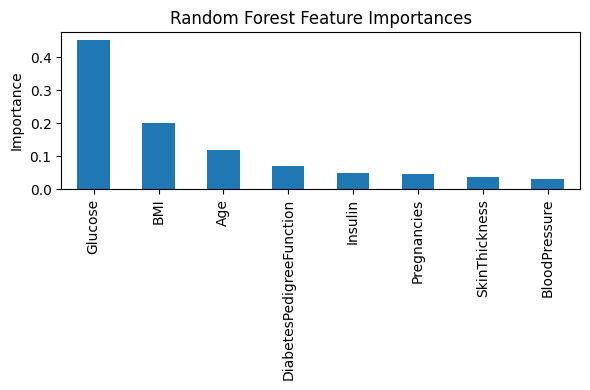

In [ ]:
plt.figure(figsize=(6,4))
importances.plot(kind='bar')
plt.title("Random Forest Feature Importances")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

### Cross Validation

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


In [ ]:
# Evaluate the three (already-tuned) models via 5-fold CV on the full dataset
def cv_auc(model, X, y):
    return cross_val_score(model, X, y, cv=skf, scoring='roc_auc', n_jobs=-1)


In [ ]:
cv_scores = {
    'KNN(best)': cv_auc(best_knn, X, y),
    'DecisionTree(best)': cv_auc(best_dt, X, y),
    'RandomForest(best)': cv_auc(best_rf, X, y)
}

In [ ]:
for name, scores in cv_scores.items():
    print(f"{name}: mean AUC={scores.mean():.3f} (+/- {scores.std():.3f})")


KNN(best): mean AUC=0.822 (+/- 0.017)
DecisionTree(best): mean AUC=0.798 (+/- 0.039)
RandomForest(best): mean AUC=0.831 (+/- 0.027)


### The Fun-er Stuff

Q11

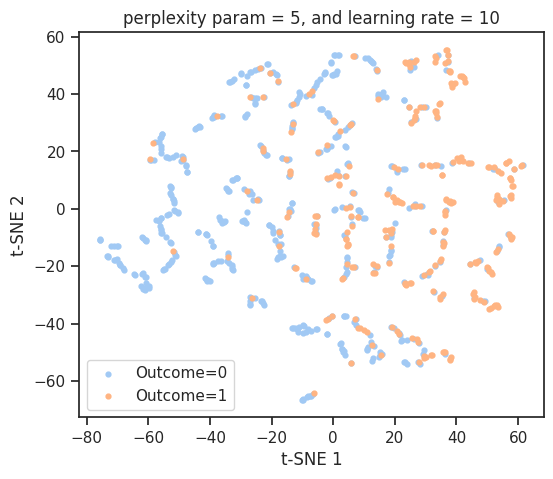

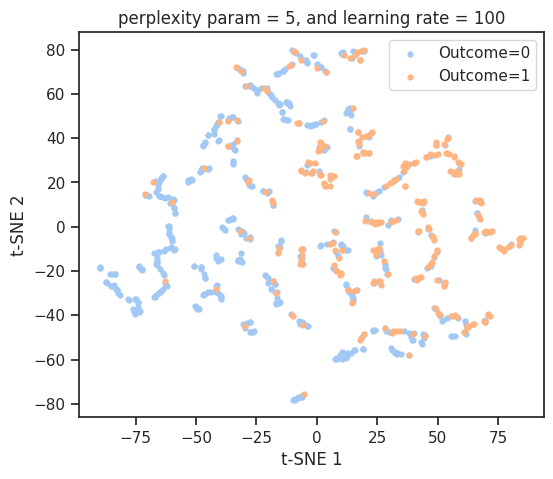

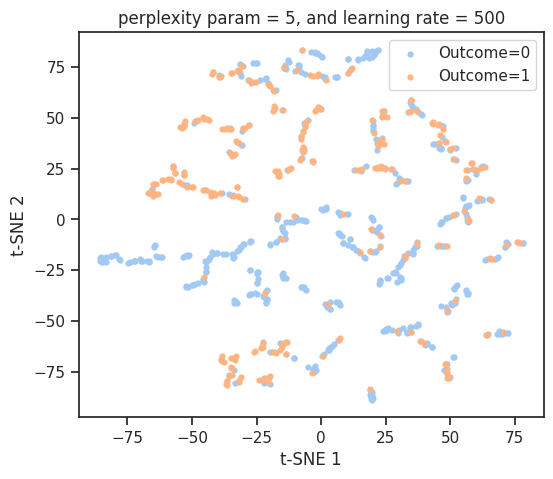

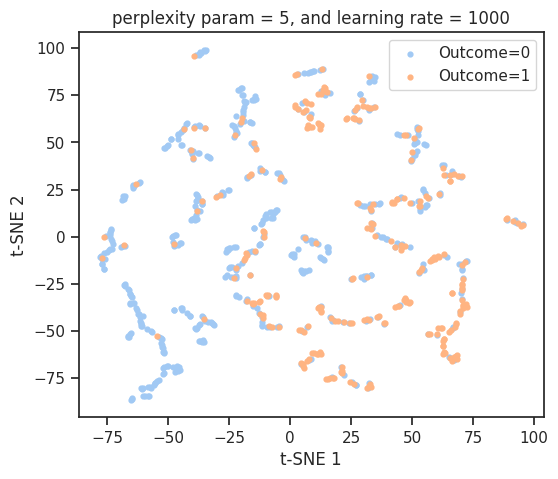

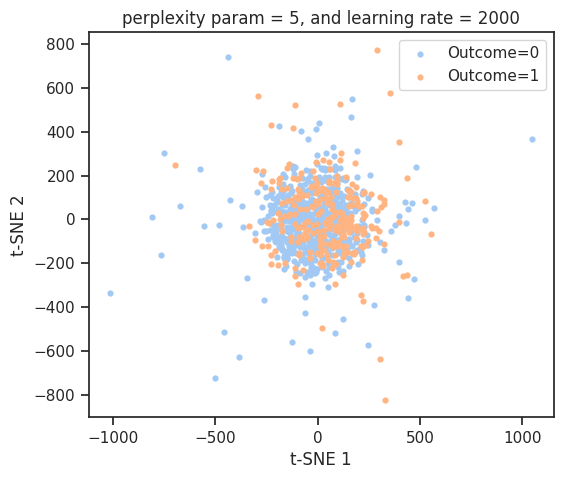

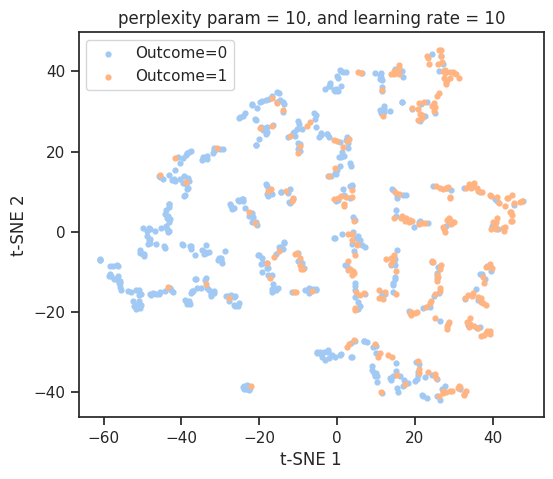

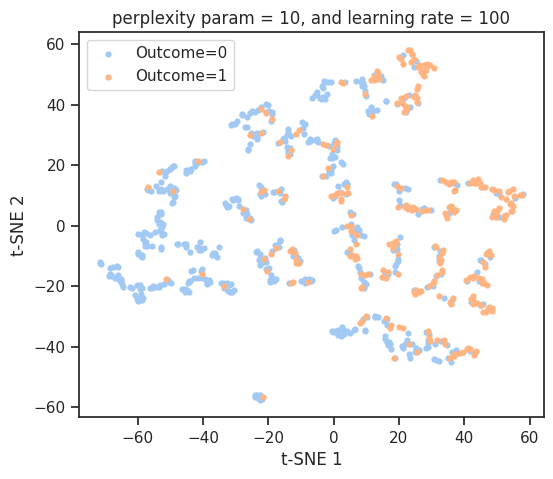

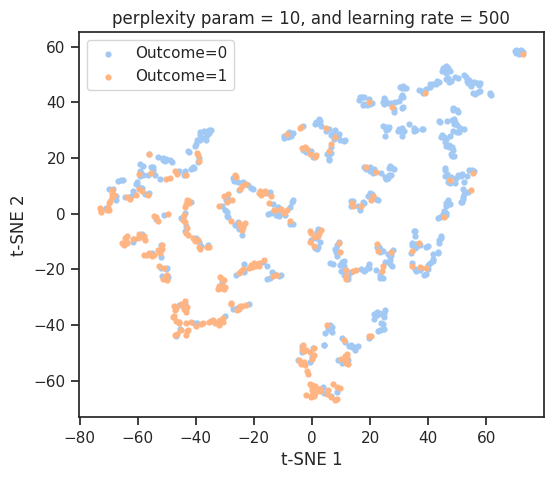

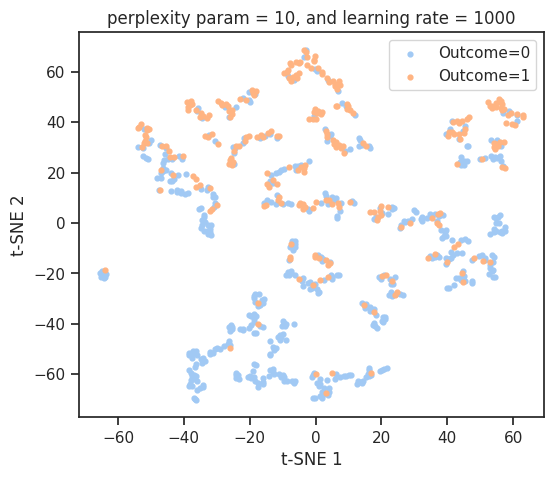

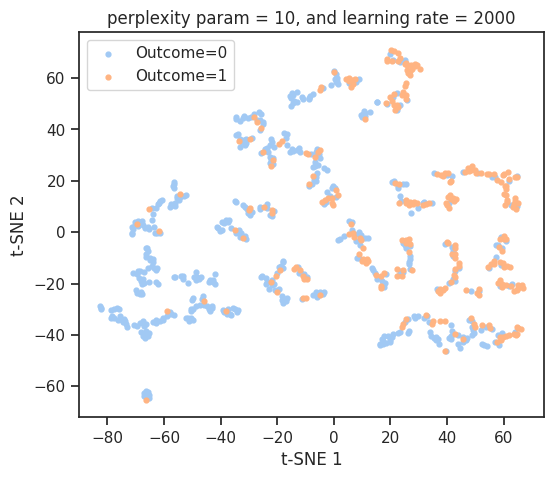

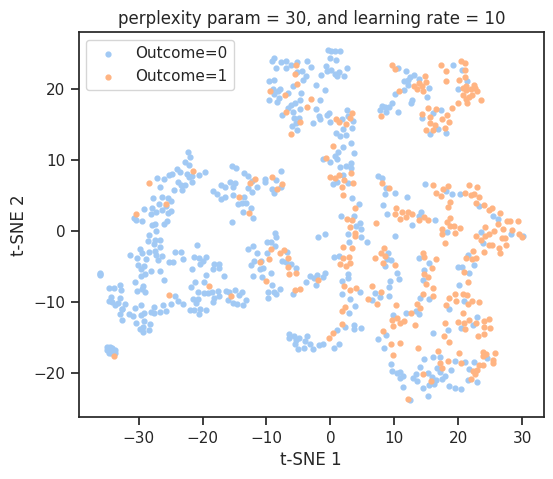

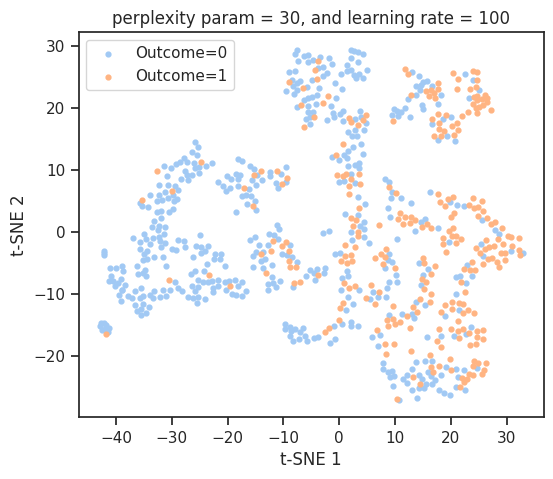

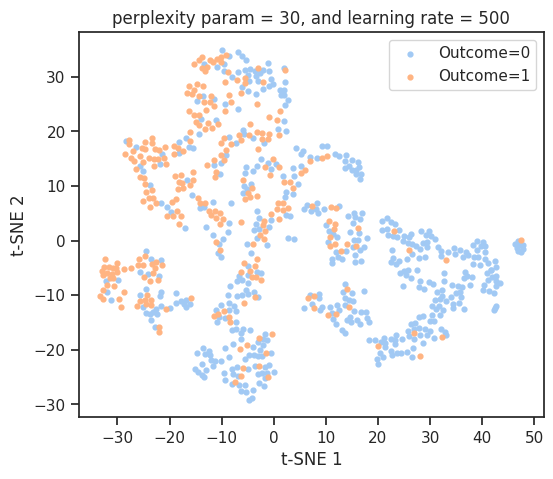

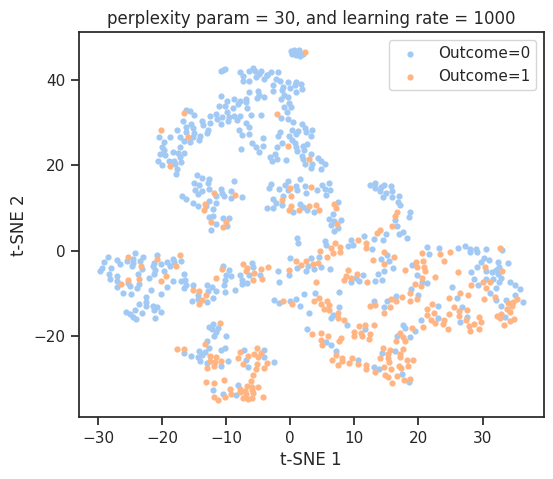

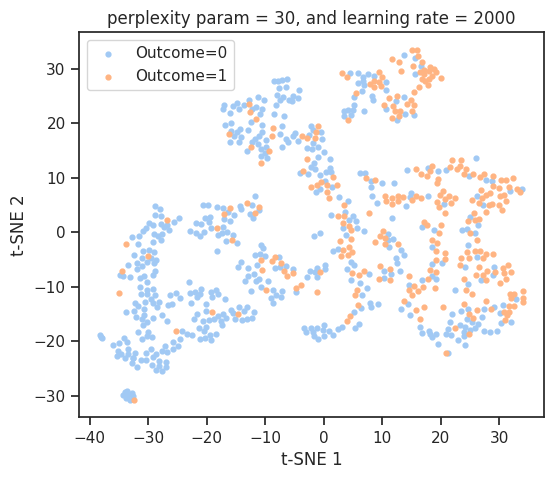

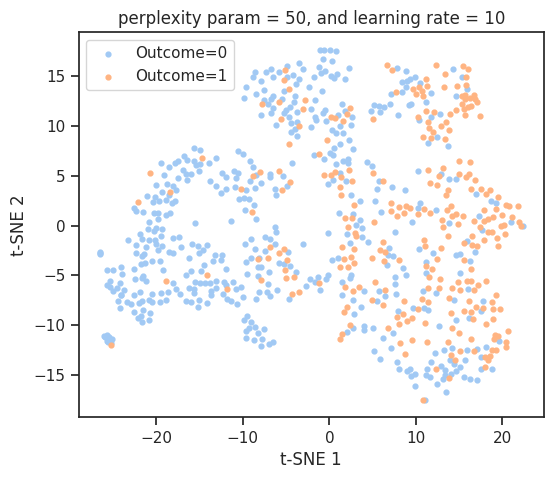

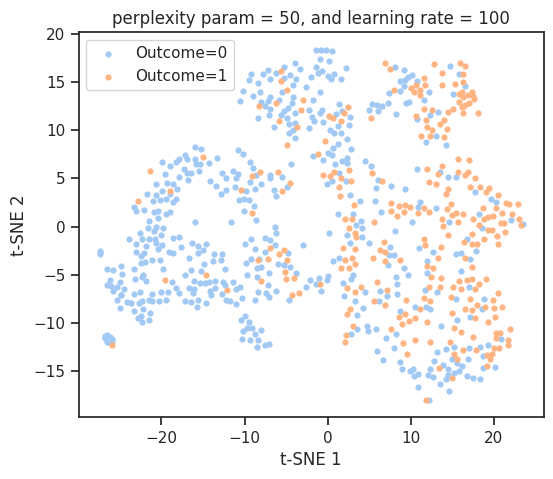

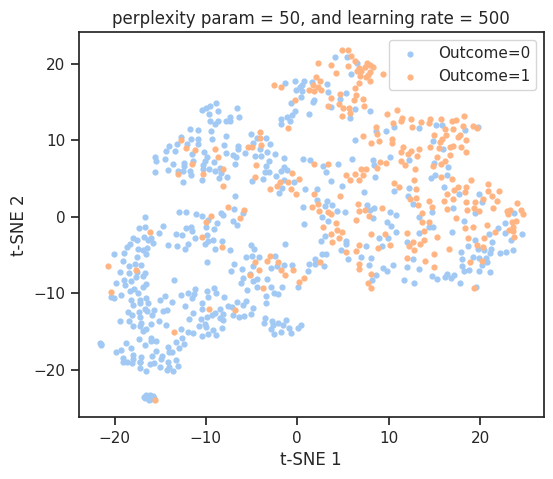

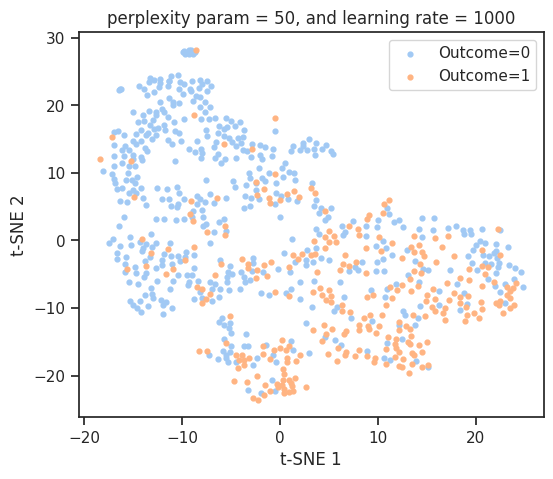

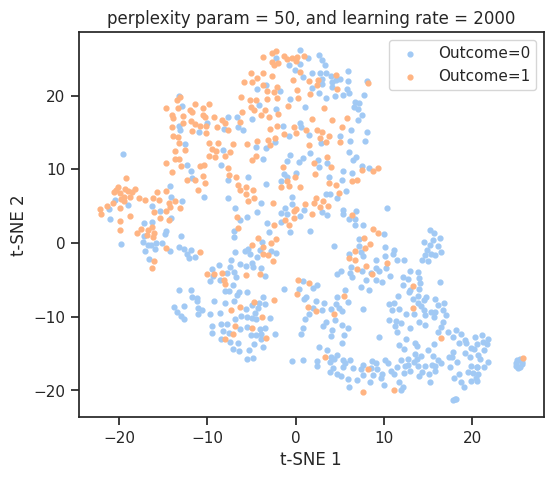

In [ ]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


#implement stuff here for Q11
#Standardization
FEATURES = ['Glucose','BMI','Age']
TARGET = 'Outcome'

X = df[FEATURES].copy()
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    #TO-DO: write this code
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y

)


Xs = StandardScaler().fit_transform(X)
Xp = PCA(n_components=min(2, X.shape[1]), random_state=RANDOM_STATE).fit_transform(Xs)
Xp = PCA(n_components=min(2, X.shape[1]), random_state=RANDOM_STATE).fit_transform(Xs)


#t-SNE
for my_perplexity in [5,10,30,50]:
  for learning_rate in [10,100,500,1000,2000]:

    tsne = TSNE(n_components=2, perplexity=my_perplexity, learning_rate=learning_rate, init='pca', random_state=RANDOM_STATE)

    X_emb = tsne.fit_transform(Xp)

    plt.figure(figsize=(6,5))
    for label in sorted(y.unique()):
        mask = (y.values == label)
        plt.scatter(X_emb[mask,0], X_emb[mask,1], label=f"Outcome={label}", s=12)
    mytitle = f"perplexity param = {my_perplexity}, and learning rate = {learning_rate}"
    plt.title(mytitle)
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.legend()
    plt.show()






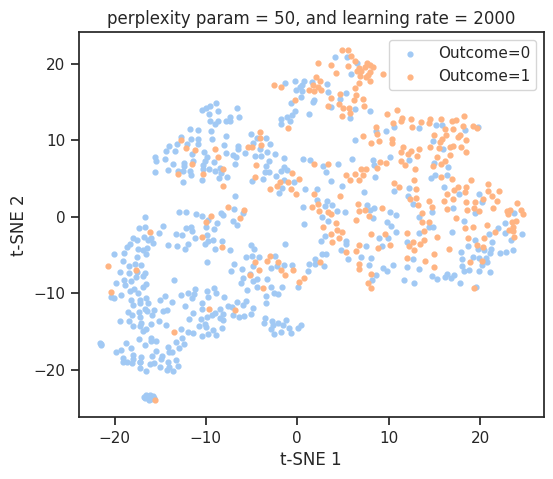

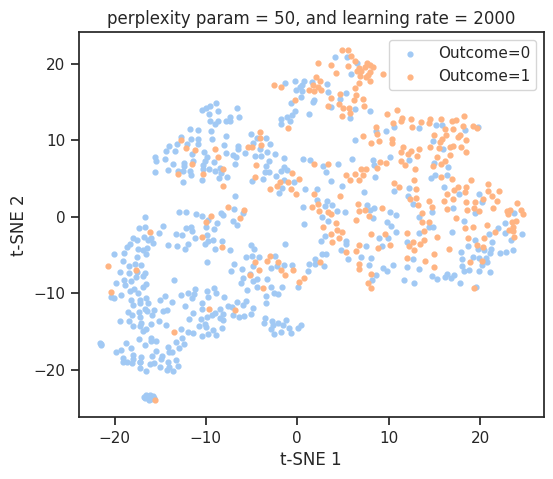

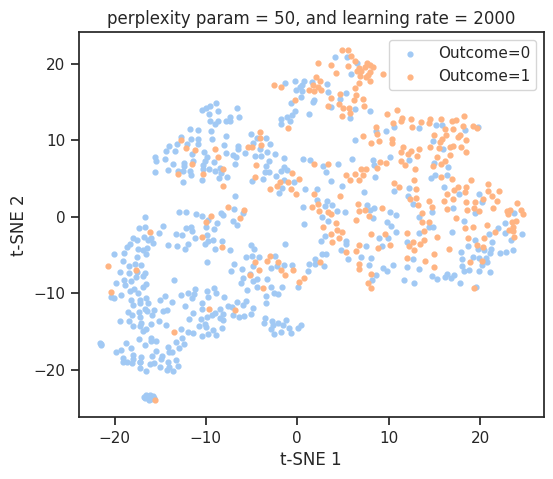

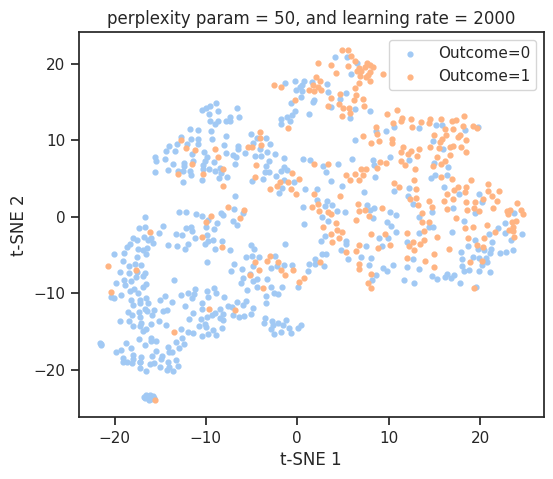

In [ ]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


#implement stuff here for Q11
#Standardization
FEATURES = ['Glucose','BMI','Age']
TARGET = 'Outcome'

X = df[FEATURES].copy()
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    #TO-DO: write this code
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y

)


Xs = StandardScaler().fit_transform(X)
Xp = PCA(n_components=min(2, X.shape[1]), random_state=RANDOM_STATE).fit_transform(Xs)
Xp = PCA(n_components=min(2, X.shape[1]), random_state=RANDOM_STATE).fit_transform(Xs)


#t-SNE
for random_state in [1,30,55,60]:
  np.random.seed(random_state)

  tsne = TSNE(n_components=2, perplexity=my_perplexity, learning_rate= 500, init='pca', random_state=RANDOM_STATE)

  X_emb = tsne.fit_transform(Xp)

  plt.figure(figsize=(6,5))
  for label in sorted(y.unique()):
      mask = (y.values == label)
      plt.scatter(X_emb[mask,0], X_emb[mask,1], label=f"Outcome={label}", s=12)
  mytitle = f"perplexity param = {my_perplexity}, and learning rate = {learning_rate}"
  plt.title(mytitle)
  plt.xlabel("t-SNE 1")
  plt.ylabel("t-SNE 2")
  plt.legend()
  plt.show()






##### Threshold Optimization

In [ ]:
from sklearn.metrics import brier_score_loss, precision_score, f1_score
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression

In [ ]:
y_proba = grid_rf.predict_proba(X_test)[:, 1]
prob_true, prob_pred = calibration_curve(y_test, y_proba, n_bins=10, strategy="quantile")

Calibration curves (reliability diagrams)

See:
https://scikit-learn.org/stable/modules/calibration.html

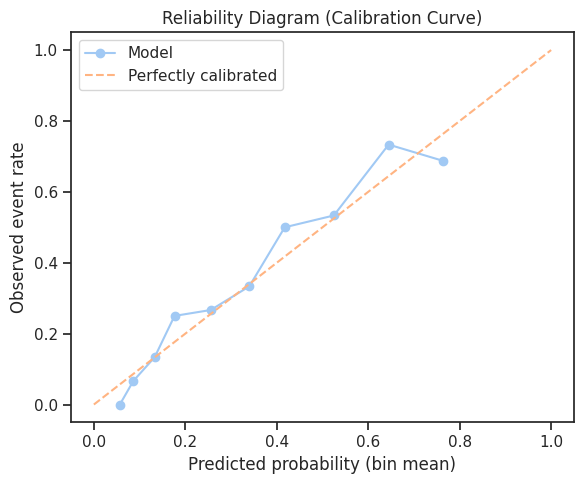

In [ ]:
plt.figure(figsize=(6,5))
plt.plot(prob_pred, prob_true, marker='o', label="Model")
plt.plot([0,1], [0,1], linestyle='--', label="Perfectly calibrated")
plt.xlabel("Predicted probability (bin mean)")
plt.ylabel("Observed event rate")
plt.title("Reliability Diagram (Calibration Curve)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# 2) Brier score
brier = brier_score_loss(y_test, y_proba)
print(f"Brier score: {brier:.4f}")

Brier score: 0.1688


In [ ]:
# 3) Calibration-in-the-large (intercept) and calibration slope
#    Fit logistic regression: logit(P(y=1)) ~ alpha + beta * logit(p_hat)
def _logit(p, eps=1e-6):
    p = np.clip(p, eps, 1-eps)
    return np.log(p/(1-p))

logit_phat = _logit(y_proba).reshape(-1,1)

In [ ]:
lr = LogisticRegression(solver='lbfgs', C=1e6, max_iter=10000) # Large C ~= unpenalized
lr.fit(logit_phat, y_test)
cal_intercept = lr.intercept_[0]
cal_slope = lr.coef_[0][0]
print(f"Calibration intercept (ideal ≈ 0): {cal_intercept:.3f}")
print(f"Calibration slope (ideal ≈ 1): {cal_slope:.3f}")

Calibration intercept (ideal ≈ 0): 0.102
Calibration slope (ideal ≈ 1): 1.080


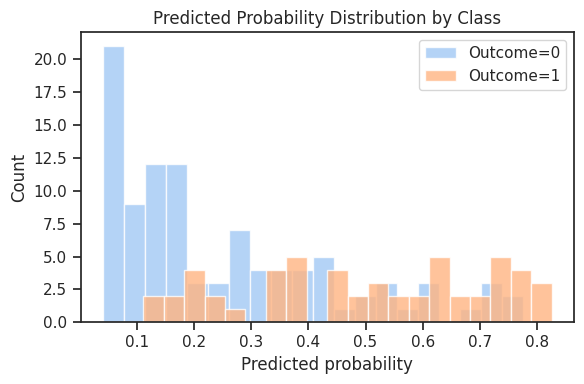

In [ ]:
# 4) Histogram of predicted probabilities (to inspect spread)
plt.figure(figsize=(6,4))
plt.hist(y_proba[y_test==0], bins=20, alpha=0.8, label='Outcome=0')
plt.hist(y_proba[y_test==1], bins=20, alpha=0.8, label='Outcome=1')
plt.xlabel("Predicted probability")
plt.ylabel("Count")
plt.title("Predicted Probability Distribution by Class")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.calibration import CalibratedClassifierCV

In [ ]:
#wrapping grid RF with post-hoc calibration:
cal_model = CalibratedClassifierCV(estimator=best_rf , cv=10, method='isotonic')
cal_model.fit(X_train, y_train)

y_proba_cal = cal_model.predict_proba(X_test)[:,1]

In [ ]:
# Recompute calibration curve post-calibration
prob_true_c, prob_pred_c = calibration_curve(y_test, y_proba_cal, n_bins=10, strategy="quantile")


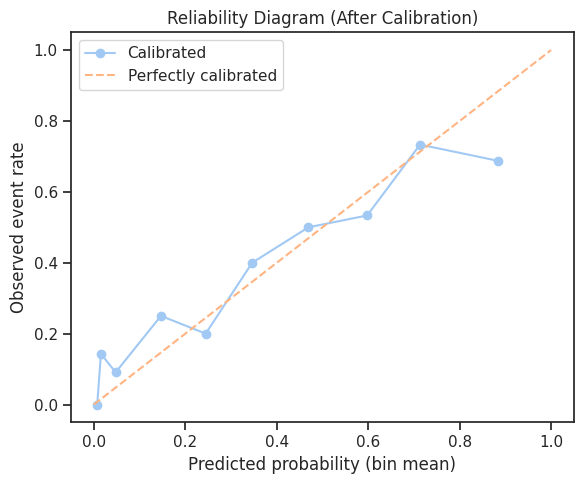

In [ ]:
plt.figure(figsize=(6,5))
plt.plot(prob_pred_c, prob_true_c, marker='o', label="Calibrated")
plt.plot([0,1], [0,1], linestyle='--', label="Perfectly calibrated")
plt.xlabel("Predicted probability (bin mean)")
plt.ylabel("Observed event rate")
plt.title("Reliability Diagram (After Calibration)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Compare AUC and Brier pre/post
auc_pre = roc_auc_score(y_test, y_proba)
auc_post = roc_auc_score(y_test, y_proba_cal)
brier_pre = brier_score_loss(y_test, y_proba)
brier_post = brier_score_loss(y_test, y_proba_cal)
print(f"AUC pre: {auc_pre:.3f} | post: {auc_post:.3f}")
print(f"Brier pre: {brier_pre:.4f} | post: {brier_post:.4f}")

AUC pre: 0.812 | post: 0.809
Brier pre: 0.1688 | post: 0.1721


*texto en cursiva*##### Sensitivity Threshold

In [ ]:
#Implement a tunable sensitivity threshold. Use it to support your ans for Q13.
y_proba_cal = cal_model.predict_proba(X_test)[:,1]

def predict_with_threshold(probabilities, threshold):
    return (probabilities >= threshold).astype(int)

# Example: Using a custom threshold of 0.3
custom_threshold = 0.7
y_pred_tuned = predict_with_threshold(y_proba_cal, custom_threshold)


THE END OF LAB C2/D1.